# Project 2: Evolutionary Algorithms
Machine Learning T-504-ITML 

Group: Dagur Smári (dagurss24@ru.is) and Kamil Michal (kamil24@ru.is)

## The Setup

In [1]:
import random
import numpy as np
seed = 42240 #last 5 digit of smallest student number
random.seed(seed)
np.random.seed(seed)
import matplotlib.pyplot as plt

---
## Task 1: 6-bit Representation of Integers

In [2]:
## Functions to go from phenome type to genotype and back
def geno_to_pheno(individuals):
    return [int("".join(map(str, individual)), 2) for individual in individuals]

def pheno_to_geno(x_values):
    return [[int(bit) for bit in format(x_value, '06b')] for x_value in x_values]

### 1.1 Initialization function

In [3]:
def initialization_population(pop_size):
    
    population = []
    for i in range(pop_size):
        digit = random.randint(0, 63)
        population.append(digit)
    return pheno_to_geno(population)

**Subtask: generate 4 individuals**

In [4]:
test_population = initialization_population(4)
print("Individuals:", test_population)
print("As integers:", geno_to_pheno(test_population))
print("Output type: a", type(test_population).__name__, "of", type(test_population[0]).__name__ + "s",
      "(each of length", len(test_population[0]), ")")

Individuals: [[0, 0, 0, 1, 0, 0], [1, 1, 1, 0, 0, 0], [0, 1, 1, 1, 0, 0], [1, 0, 0, 0, 0, 1]]
As integers: [4, 56, 28, 33]
Output type: a list of lists (each of length 6 )


### 1.2 Fitness function

In [5]:
def fitness(individuals):

    # Takes in geno values [x, x, x, x, x, x]
    x_values = geno_to_pheno(individuals)
    result = []
    
    for x in x_values:
        
        if x >= 32:
            y = x - 64
        else:
            y = x
            
        fitness_value = (
            -0.00008333 * pow(y, 6)
            - 0.001 * pow(y, 5)
            + 0.09375 * pow(y, 4)
            + 1.16667 * pow(y, 3)
            - 19.53125 * pow(y, 2)
            - 234.375 * y
            + 8350
        )

        result.append(fitness_value)    

    #return pheno values
    return result

**Subtask: Check for individual = [[0, 1, 0, 1, 0, 1]]**

In [6]:
individual = [[0, 1, 0, 1, 0, 1]]
print("Expected fitness value: 12620.97")
print("Fitness value: " + str(round(fitness(individual)[0], 2)))

Expected fitness value: 12620.97
Fitness value: 12620.98


**Subtask: Fitness landscape and min/max x-values**

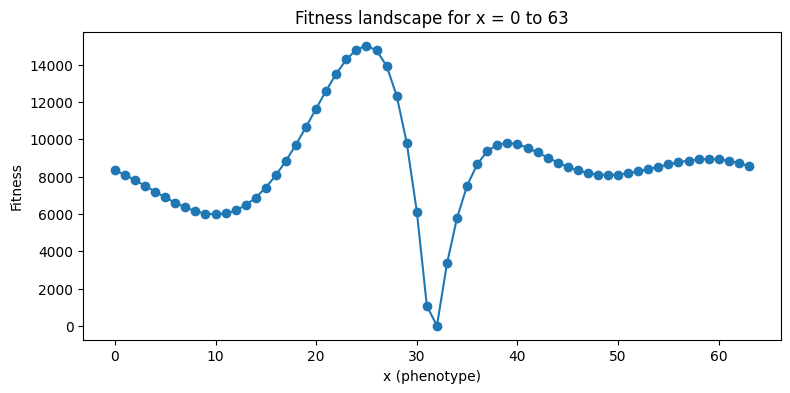

Max fitness: 15024.04 at x = 25 or [0, 1, 1, 0, 0, 1]
Min fitness: 4.08 at x = 32 or [1, 0, 0, 0, 0, 0]


In [7]:
# Plot of the landscape
x_values = list(range(64))
fitness_values = fitness(pheno_to_geno(x_values))

plt.figure(figsize=(9, 4))
plt.plot(x_values, fitness_values, marker="o")
plt.xlabel("x (phenotype)")
plt.ylabel("Fitness")
plt.title("Fitness landscape for x = 0 to 63")
plt.show()

# Which x gives min and max fitness
x_max = x_values[fitness_values.index(max(fitness_values))]
x_min = x_values[fitness_values.index(min(fitness_values))]

print("Max fitness:", round(max(fitness_values), 2), "at x =", x_max, "or", pheno_to_geno([x_max])[0])
print("Min fitness:", round(min(fitness_values), 2), "at x =", x_min, "or", pheno_to_geno([x_min])[0])

### 1.3 Parent selection function

In [8]:
def parent_selection(individuals, fitness_values):

    total_fitness = sum(fitness_values)
    fitness_val_probabilities = []

    for i in range(len(fitness_values)):
        fitness_val_probabilities.append(fitness_values[i] / total_fitness)

    selected = np.random.choice(len(individuals),size=len(individuals),replace=True,p=fitness_val_probabilities)

    parents = []
    for i in selected:
        parents.append(list(individuals[i]))
    return parents

## Windowing needed for bonus

**Subtask: Testing on four individuals**

In [9]:
# Use x_values, fitness_values, x_min and x_max from fitness cell

# the 2 x values with fitness closest to the middle of the fitness range
middle = (min(fitness_values) + max(fitness_values)) / 2
closest = sorted(x_values, key=lambda x: abs(fitness_values[x] - middle))[:2]

test_x = [x_min, x_max] + closest
test_individuals = pheno_to_geno(test_x)
test_fitness = fitness(test_individuals)

for x, g, f in zip(test_x, test_individuals, test_fitness):
    print(f"x = {x} (genotype = {g}) fitness = {round(f, 2)} probability = {round((f / sum(test_fitness)), 2)}")

parents = parent_selection(test_individuals, test_fitness)
print("------------------------")
print("Parents: ", parents)
print("As x: ", geno_to_pheno(parents))

x = 32 (genotype = [1, 0, 0, 0, 0, 0]) fitness = 4.08 probability = 0.0
x = 25 (genotype = [0, 1, 1, 0, 0, 1]) fitness = 15024.04 probability = 0.5
x = 3 (genotype = [0, 0, 0, 0, 1, 1]) fitness = 7509.88 probability = 0.25
x = 35 (genotype = [1, 0, 0, 0, 1, 1]) fitness = 7519.29 probability = 0.25
------------------------
Parents:  [[0, 0, 0, 0, 1, 1], [0, 1, 1, 0, 0, 1], [0, 1, 1, 0, 0, 1], [0, 1, 1, 0, 0, 1]]
As x:  [3, 25, 25, 25]


### 1.4 Crossover

In [10]:
def one_point_crossover(parents, crossover_prob):
     
    off_spring = []

    for i in range(0, len(parents), 2):

        if i == len(parents) - 1:
            off_spring.append(parents[i].copy())
            break

        number = random.random()   
        if number > crossover_prob:
            off_spring.append(parents[i].copy())
            off_spring.append(parents[i+1].copy())
            continue

        crossover_point = random.randint(1, len(parents[i]) - 1)

        offspring1 = parents[i]
        offspring2 = parents[i+1]

        new_offspring1 = offspring1[:crossover_point] + offspring2[crossover_point:]
        new_offspring2 = offspring2[:crossover_point] + offspring1[crossover_point:]

        off_spring.append(new_offspring1)
        off_spring.append(new_offspring2)

    return off_spring

**Subtask: Crossover of two parents**

In [11]:
test_parents = [[0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1]]
children = one_point_crossover(test_parents, 1.0)

print("Parents:  ", test_parents)
print("Offspring:", children)
cut = children[0].index(1)
print("Cut point: after gene", cut)
print("With pc = 0:", one_point_crossover(test_parents, 0.0))

Parents:   [[0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1]]
Offspring: [[0, 1, 1, 1, 1, 1], [1, 0, 0, 0, 0, 0]]
Cut point: after gene 1
With pc = 0: [[0, 0, 0, 0, 0, 0], [1, 1, 1, 1, 1, 1]]


### 1.5 Mutation

In [12]:
def mutation(individuals, mutation_prob):
    
    mutated = []

    for i in individuals:
        new_individual = i.copy()

        for j in range(len(new_individual)):
            number = random.random()
            if number <= mutation_prob:
                # flip the gene
                new_individual[j] = 1 - new_individual[j]

        mutated.append(new_individual)

    return mutated

**Subtask: mutation of one individual**

In [13]:
individual = [[0, 1, 0, 1, 0, 1]]
print("Original individual:", individual[0])
print("-----------")
print("Individual after mutation with 0.2% pm:", mutation(individual, 0.2)[0])
print("Individual after mutation with 0.9% pm:", mutation(individual, 0.9)[0])

Original individual: [0, 1, 0, 1, 0, 1]
-----------
Individual after mutation with 0.2% pm: [1, 1, 0, 0, 0, 0]
Individual after mutation with 0.9% pm: [1, 0, 1, 0, 1, 1]


Comment on whether the number of bit flips is expected

(maybe do more/better tests)

### 1.6 Survivor selection

In [14]:
def survivor_selection(individuals, offspring, fitness_individuals, fitness_offspring):
    survivors = []

    all_individuals = individuals + offspring
    all_fitness = list(fitness_individuals) + list(fitness_offspring)

    # sort positions from highest to lowest
    for k in range(len(individuals)):
        # find the fittest one left, move it to the survivors
        best = all_fitness.index(max(all_fitness))
        survivors.append(all_individuals.pop(best))
        all_fitness.pop(best)

    return survivors

**Subtask: Test fitter individual**

In [15]:
parent = [[0, 1, 0, 1, 0, 1]]   # x = 21
child = [[0, 1, 1, 0, 0, 1]]     # x = 25
survivor = survivor_selection(parent, child, fitness(parent), fitness(child))

print("Parent:", parent[0], "Fitness =", round(fitness(parent)[0], 2))
print("Offspring:", child[0], "Fitness =", round(fitness(child)[0], 2))
print("------------")
print("Survivor:", survivor[0], "Fitness =", round(fitness(survivor)[0], 2))

Parent: [0, 1, 0, 1, 0, 1] Fitness = 12620.98
Offspring: [0, 1, 1, 0, 0, 1] Fitness = 15024.04
------------
Survivor: [0, 1, 1, 0, 0, 1] Fitness = 15024.04


### 1.7 Complete version of SGA (Loop)

In [16]:
def sga(pop_size, n_iterations, crossover_prob, mutation_prob,
        init_function=initialization_population, fitness_function=fitness,
        crossover_function=one_point_crossover, mutation_function=mutation,
        print_every=1):

    # start with random population and its fitness
    population = init_function(pop_size)
    population_fitness = fitness_function(population)

    # save the history (to show improvement)
    best_history = [max(population_fitness)]
    average_history = [sum(population_fitness) / pop_size]

    if print_every > 0:
        print(f"Iteration 0: average fitness = {round(average_history[-1], 2)}, best fitness = {round(best_history[-1], 2)}")

    for iteration in range(1, n_iterations + 1):

        # repeated steps in every iteration
        parents = parent_selection(population, population_fitness)
        offspring = crossover_function(parents, crossover_prob)
        offspring = mutation_function(offspring, mutation_prob)
        offspring_fitness = fitness_function(offspring)

        population = survivor_selection(population, offspring, population_fitness, offspring_fitness)
        population_fitness = fitness_function(population)

        # save and show the average and best fitness of this iteration
        best_history.append(max(population_fitness))
        average_history.append(sum(population_fitness) / pop_size)

        # print every # number of lines (for later tasks, can change to every 100 lines for example)
        if print_every > 0 and iteration % print_every == 0:
            print(f"Iteration {iteration}: average fitness = {round(average_history[-1], 2)}, best fitness = {round(best_history[-1], 2)}")

    return population, population_fitness, best_history, average_history

**Subtask: Display best & average fitness**

Iteration 0: average fitness = 7768.79, best fitness = 9549.33
Iteration 1: average fitness = 9361.16, best fitness = 11650.24
Iteration 2: average fitness = 9722.36, best fitness = 11650.24
Iteration 3: average fitness = 9759.42, best fitness = 11650.24
Iteration 4: average fitness = 10104.51, best fitness = 12620.98
Iteration 5: average fitness = 10959.15, best fitness = 15024.04
Iteration 6: average fitness = 12789.95, best fitness = 15024.04
Iteration 7: average fitness = 13321.47, best fitness = 15024.04
Iteration 8: average fitness = 13693.39, best fitness = 15024.04
Iteration 9: average fitness = 14545.92, best fitness = 15024.04
Iteration 10: average fitness = 15024.04, best fitness = 15024.04
Iteration 11: average fitness = 15024.04, best fitness = 15024.04
Iteration 12: average fitness = 15024.04, best fitness = 15024.04
Iteration 13: average fitness = 15024.04, best fitness = 15024.04
Iteration 14: average fitness = 15024.04, best fitness = 15024.04
Iteration 15: average fit

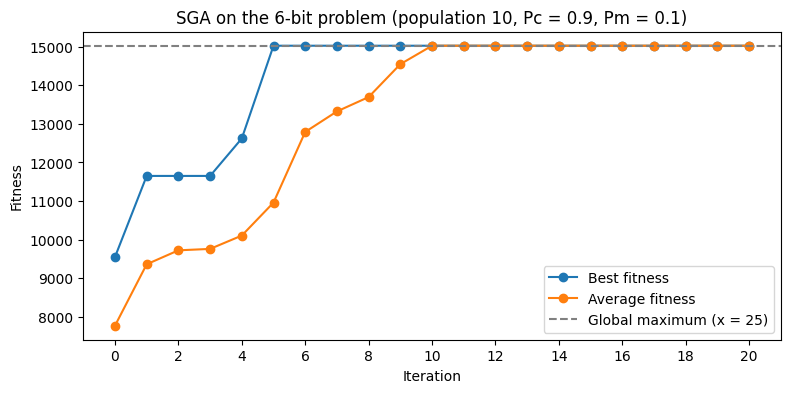

In [17]:
population, population_fitness, best_history, average_history = sga(10, 20, 0.9, 0.1)

print("------------------------")
print("Final population (x):", geno_to_pheno(population))

#Simple plot
plt.figure(figsize=(9, 4))
plt.plot(best_history, marker="o", label="Best fitness")
plt.plot(average_history, marker="o", label="Average fitness")
plt.axhline(max(fitness_values), color="grey", linestyle="--", label="Global maximum (x = 25)")
plt.xticks(range(0, len(best_history), 2))
plt.xlabel("Iteration")
plt.ylabel("Fitness")
plt.title("SGA on the 6-bit problem (population 10, Pc = 0.9, Pm = 0.1)")
plt.legend()
plt.show()

text explaining output

### 1.8 Testing SGA

In [ ]:
# ...

---
## Task 2: Knapsack for ”data 1001” data set

### 2.1 Load the data set